In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

In [3]:
df = pd.read_csv("train.csv")

In [4]:
print(df.shape)

(891, 12)


In [5]:
print(df.dtypes)

PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object


In [6]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [7]:
df.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [8]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [9]:
number_cols = df.select_dtypes(include="number").columns
categ_cols = df.select_dtypes(exclude="number").columns
print("les variables numeriques :",number_cols)
print("les variables categorielles:",categ_cols)

les variables numeriques : Index(['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare'],
      dtype='str')
les variables categorielles: Index(['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked'], dtype='str')


In [10]:
df_clean = df.copy()

In [11]:
percent_nb_manq = (df_clean.isnull().sum() / len(df_clean)) * 100
print(percent_nb_manq)

PassengerId     0.000000
Survived        0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
Age            19.865320
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
Cabin          77.104377
Embarked        0.224467
dtype: float64


In [14]:
df_clean = df_clean.drop(columns=["Cabin"])

In [15]:
df_clean["Age"] = df_clean["Age"].fillna(df_clean["Age"].median())
df_clean["Embarked"] = df_clean["Embarked"].fillna(df_clean["Embarked"].mode()[0])

In [17]:
df_clean.isna().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

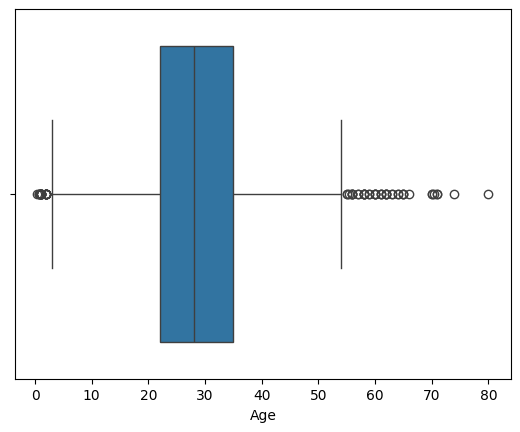

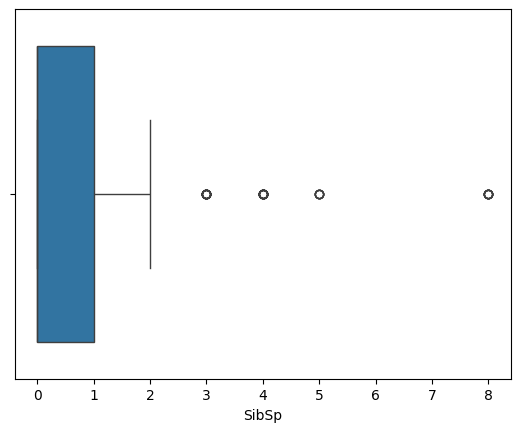

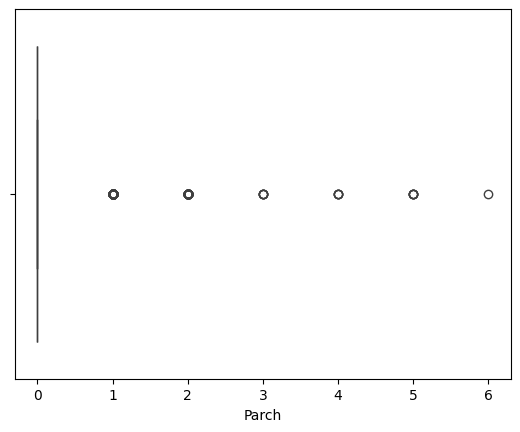

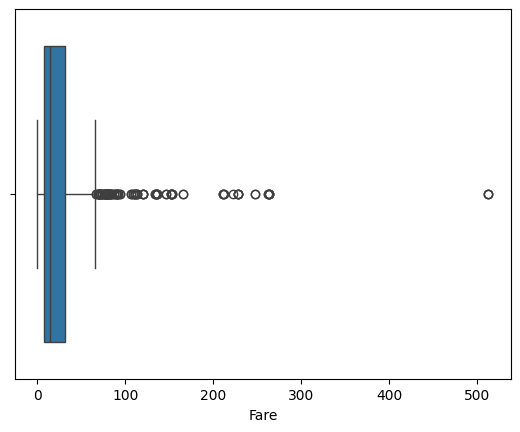

In [19]:
cols_num = ["Age", "SibSp", "Parch", "Fare"]
for i in cols_num:
  sns.boxplot(data=df_clean,x=i)
  plt.show()

In [28]:
for i in cols_num:
    Q1 = df_clean[i].quantile(0.25)
    Q3 = df_clean[i].quantile(0.75)
    IQR = Q3 - Q1
    lw = Q1 - 1.5 * IQR
    uw = Q3 + 1.5 * IQR
    df_clean[i] = np.where(df_clean[i] < lw, lw, df_clean[i])
    df_clean[i] = np.where(df_clean[i] > uw, uw, df_clean[i])

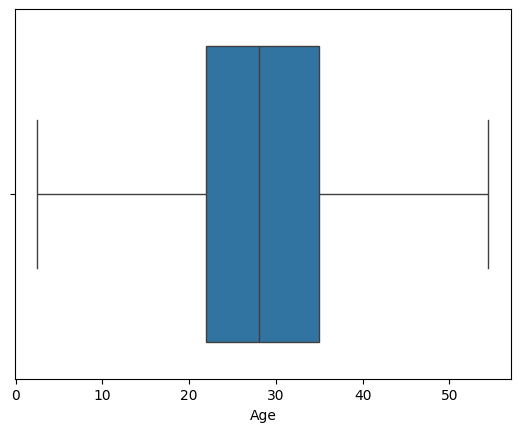

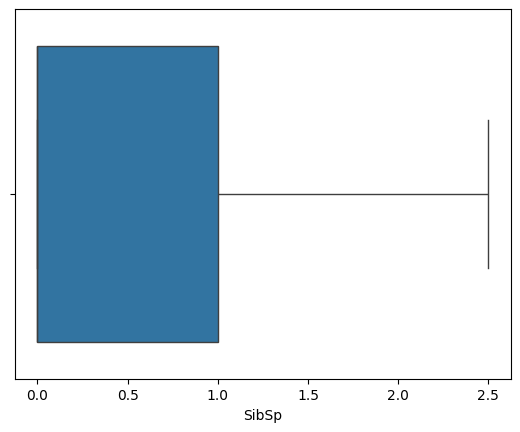

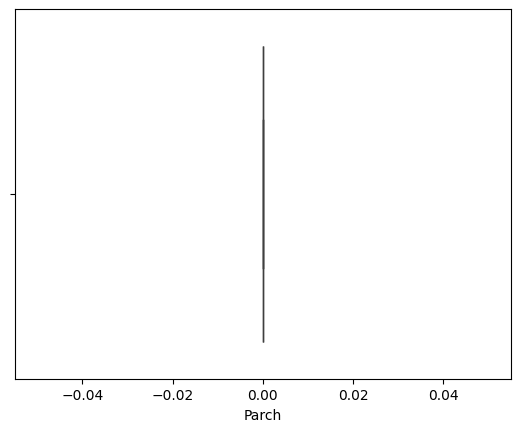

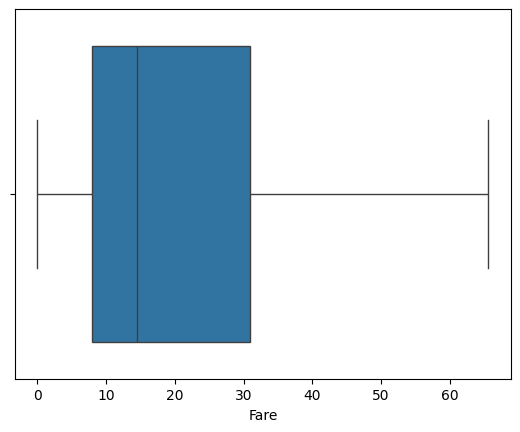

In [29]:
for i in cols_num:
  sns.boxplot(data=df_clean,x=i)
  plt.show()

In [30]:
df_clean = pd.get_dummies(df,columns=["Sex", "Embarked"],dtype=int)
print(df_clean.columns.tolist())

['PassengerId', 'Survived', 'Pclass', 'Name', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Sex_female', 'Sex_male', 'Embarked_C', 'Embarked_Q', 'Embarked_S']


In [34]:
df_clean_normalized = df_clean.copy()
df_clean_normalized[cols_num] = MinMaxScaler().fit_transform(df_clean[cols_num])

In [38]:
df_clean_std = df_clean.copy()
df_clean_std[cols_num] = StandardScaler().fit_transform(df_clean[cols_num])

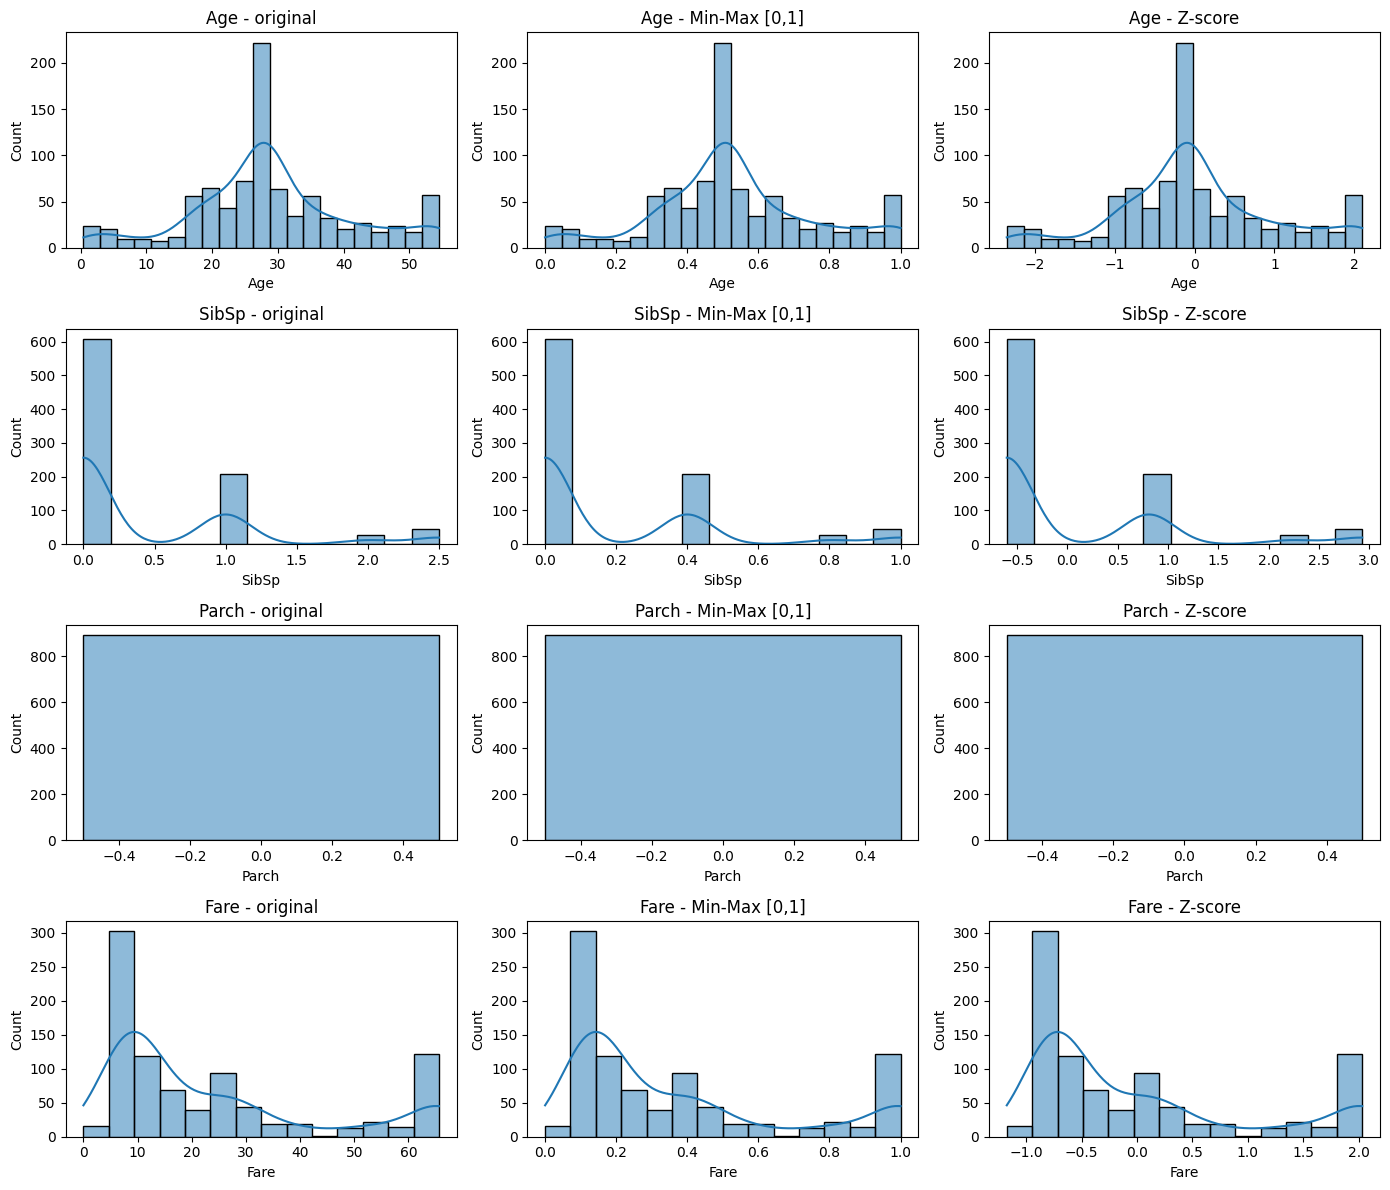

In [50]:
fig, axes = plt.subplots(len(cols_num), 3, figsize=(14, 3 * len(cols_num)))
for i, c in enumerate(cols_num):
    sns.histplot(df[c], kde=True, ax=axes[i, 0])
    axes[i, 0].set_title(f"{c} - original")
    sns.histplot(df_clean_normalized[c], kde=True, ax=axes[i, 1])
    axes[i, 1].set_title(f"{c} - Min-Max [0,1]")
    sns.histplot(df_clean_std[c], kde=True, ax=axes[i, 2])
    axes[i, 2].set_title(f"{c} - Z-score")
plt.tight_layout()
plt.show()

In [51]:
df_clean['Survived'].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [53]:
df_clean["Survived"].value_counts(normalize=True) * 100

Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64

In [54]:
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

In [56]:
X = df_clean.drop(columns=['Survived'])
y = df_clean['Survived']
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.20, stratify=y, random_state=42)

In [60]:
sc = StandardScaler().fit(X_train[cols_num])
X_train_s, X_test_s = X_train.copy(), X_test.copy()
X_train_s[cols_num] = sc.transform(X_train[cols_num])
X_test_s[cols_num]  = sc.transform(X_test[cols_num])

In [63]:
y_train.value_counts()

Survived
0    439
1    273
Name: count, dtype: int64

In [76]:
X_train_unders, y_train_unders = RandomUnderSampler(random_state=42).fit_resample(X_train_s, y_train)
print("Undersampling :", y_train_unders.value_counts())

Undersampling : Survived
0    273
1    273
Name: count, dtype: int64
